#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº0
#### Juan Martucci


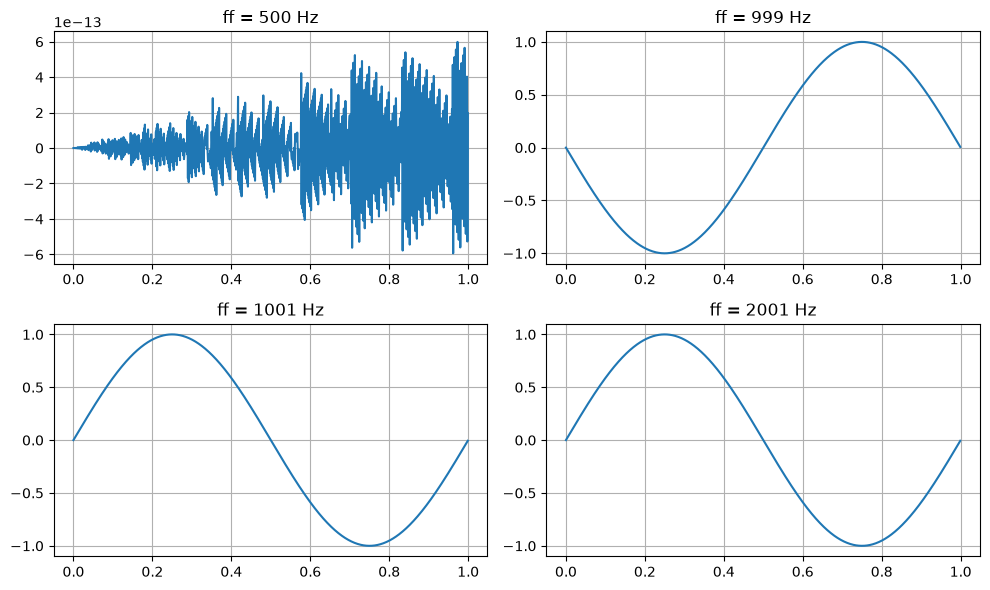

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt





def mi_funcion_sen(Vmax=1, dc=0, ff=1, ph=0, nn=1000, fs=1000):
    deltaf = fs/nn
    Ts = 1/(nn*deltaf)
    tt = np.arange(0, stop = nn*Ts, step = Ts)
    xx = Vmax*np.sin(2*np.pi*ff*tt + ph) + dc
    return tt, xx

tt1, xx1 = mi_funcion_sen(ff=500,  nn=1000, fs=1000)
tt2, xx2 = mi_funcion_sen(ff=999,  nn=1000, fs=1000)
tt3, xx3 = mi_funcion_sen(ff=1001, nn=1000, fs=1000)
tt4, xx4 = mi_funcion_sen(ff=2001, nn=1000, fs=1000)

fig, axs = plt.subplots(2, 2, figsize=(10, 6))

axs[0,0].plot(tt1, xx1)
axs[0,0].set_title("ff = 500 Hz")
axs[0,0].grid(True)

axs[0,1].plot(tt2, xx2)
axs[0,1].set_title("ff = 999 Hz")
axs[0,1].grid(True)

axs[1,0].plot(tt3, xx3)
axs[1,0].set_title("ff = 1001 Hz")
axs[1,0].grid(True)

axs[1,1].plot(tt4, xx4)
axs[1,1].set_title("ff = 2001 Hz")
axs[1,1].grid(True)


plt.tight_layout()

## Conclusion

**ff = 500 Hz:** La frecuencia de la señal (ff) cae justo en el borde de Nyquist (fs/2).El seno se muestrea exactamente en los puntos donde vale cero, dando una señal nula. Lo que se ve en el grafico es ruido.

**ff = 999 Hz:** En este caso la ff supera fs/2, por lo que sufre aliasing. Se ve en el grafico una señal con frecuencia |999 - 1000| = 1 Hz.

**ff = 1001 Hz:** Mismo fenomeno que en ff = 999Hz, la señal se ve con la misma frecuencia por estar a la misma distancia de 1000Hz, resultando un grafico practicamente identico pero con la fase opuesta

**ff = 2001 Hz:** El alias se calcula respecto de la copia más cercana del espectro (2000 Hz = 2·fs), dando otra vez una señal de  |2001 - 2000| = 1 Hz.

## Bonus

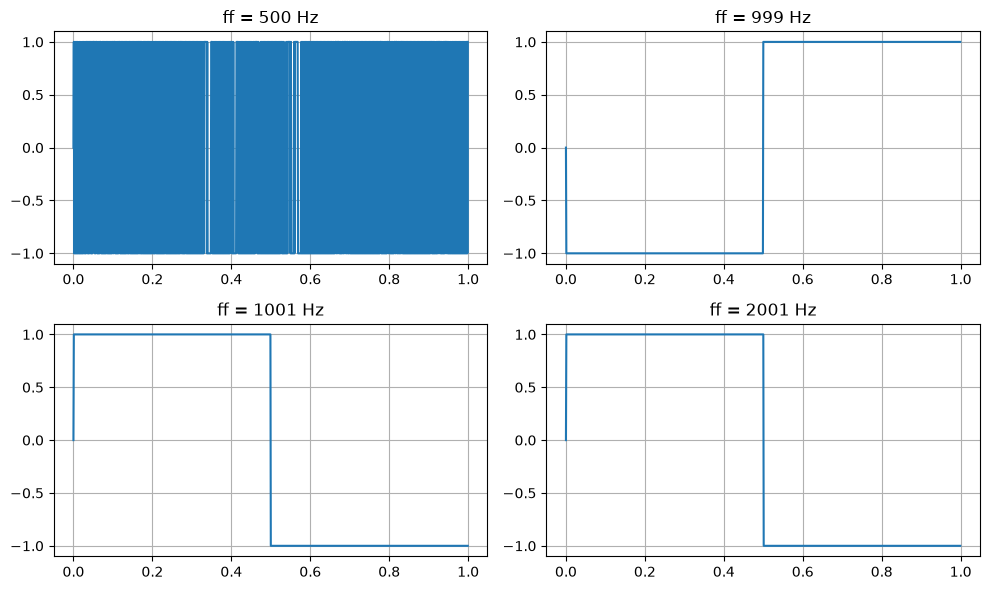

In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt





def mi_funcion_cuadrada(vmax=1, dc=0, ff=1, ph=0, nn=1000, fs=1000):
    deltaf = fs/nn
    Ts = 1/(nn*deltaf)
    tt = np.arange(0, stop=nn * Ts, step=Ts)
    xx = vmax * np.sign(np.sin(2 * np.pi * ff * tt + ph)) + dc
    return tt, xx

tt1, xx1 = mi_funcion_cuadrada(ff=500,  nn=1000, fs=1000)
tt2, xx2 = mi_funcion_cuadrada(ff=999,  nn=1000, fs=1000)
tt3, xx3 = mi_funcion_cuadrada(ff=1001, nn=1000, fs=1000)
tt4, xx4 = mi_funcion_cuadrada(ff=2001, nn=1000, fs=1000)

fig, axs = plt.subplots(2, 2, figsize=(10, 6))

axs[0,0].plot(tt1, xx1)
axs[0,0].set_title("ff = 500 Hz")
axs[0,0].grid(True)

axs[0,1].plot(tt2, xx2)
axs[0,1].set_title("ff = 999 Hz")
axs[0,1].grid(True)

axs[1,0].plot(tt3, xx3)
axs[1,0].set_title("ff = 1001 Hz")
axs[1,0].grid(True)

axs[1,1].plot(tt4, xx4)
axs[1,1].set_title("ff = 2001 Hz")
axs[1,1].grid(True)


plt.tight_layout()

#### ff = 500 Hz

Para crear la funcion cuadrada se uso np.sign sobre la señal senoidal. Este comando asigna +1 a los valores positivos, -1 a los negativos. En ff = 500 HZ, la funcion seno es cero, pero debido a la precision de python no devuelve este valor exacto, sino valores muy chicos cercanos, positivos como negativos. El comando np.sign los redondea, generando el bloque del grafico. Los demas casos siguen la misma logica de aliasing que en el caso de la funcion senoidal.